In [11]:
from pathlib import Path
PROJECT = Path.cwd().parent
import sys
print(sys.executable)

import ultralytics, cv2, supervision, pandas, numpy, sklearn, mplsoccer, plotly
print("ultralytics", ultralytics.__version__)
print("opencv", cv2.__version__)
print("supervision", supervision.__version__)
print("all imports OK")

c:\Users\seree\AppData\Local\Programs\Python\Python313\python.exe
ultralytics 8.4.174
opencv 5.0.0
supervision 0.30.8
all imports OK


In [12]:
from pathlib import Path
import yaml

PROJECT = Path.cwd().parent          # notebooks/ lives one level below the project
DET = PROJECT / "data" / "detection"

with open(DET / "data.yaml") as f:
    cfg = yaml.safe_load(f)

print(cfg["names"])                  # expect ['Ball', 'Player', 'Ref']
for split in ["train", "valid", "test"]:
    n = len(list((DET / split / "images").glob("*")))
    print(split, n, "images")

['Ball', 'Player', 'Ref']
train 103 images
valid 28 images
test 19 images


In [13]:
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

names = cfg["names"]
rows = []
for split in ["train", "valid", "test"]:
    for lbl in (DET / split / "labels").glob("*.txt"):
        img_path = next((DET / split / "images").glob(lbl.stem + ".*"), None)
        if img_path is None:
            continue
        W, H = Image.open(img_path).size
        for line in lbl.read_text().splitlines():
            p = line.split()
            if len(p) < 5:
                continue
            c, cx, cy, w, h = int(p[0]), *map(float, p[1:5])
            rows.append(dict(split=split, file=lbl.stem, cls=names[c],
                             w_px=w * W, h_px=h * H, img_w=W, img_h=H))

df = pd.DataFrame(rows)
print(len(df), "boxes")
df.head()

1989 boxes


,split,file,cls,w_px,h_px,img_w,img_h
0,train,USA_NED-Qatar2022_mp4-0_jpg.rf.eedd993d9dde9db...,Player,71.99,124.26,1920,1080
1,train,USA_NED-Qatar2022_mp4-0_jpg.rf.eedd993d9dde9db...,Player,47.82,106.56,1920,1080
2,train,USA_NED-Qatar2022_mp4-0_jpg.rf.eedd993d9dde9db...,Player,49.95,95.41,1920,1080
3,train,USA_NED-Qatar2022_mp4-0_jpg.rf.eedd993d9dde9db...,Player,59.57,129.72,1920,1080
4,train,USA_NED-Qatar2022_mp4-0_jpg.rf.eedd993d9dde9db...,Player,57.89,110.70,1920,1080


cls,Ball,Player,Ref
split,,,
train,86,1167,89
valid,23,346,32
test,17,216,13


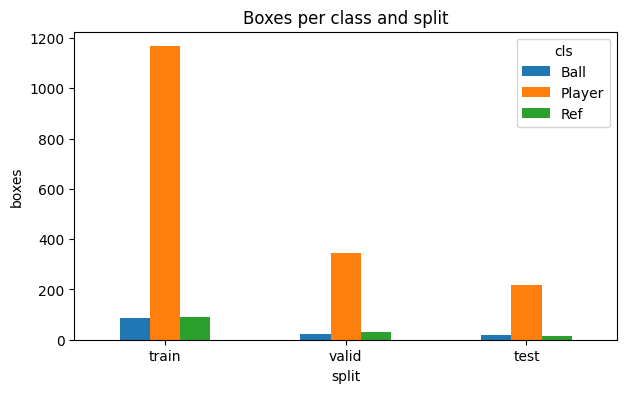

In [14]:
counts = (df.groupby(["split", "cls"]).size()
            .unstack(fill_value=0)
            .reindex(["train", "valid", "test"]))
display(counts)

counts.plot(kind="bar", figsize=(7, 4))
plt.title("Boxes per class and split")
plt.ylabel("boxes")
plt.xticks(rotation=0)
plt.savefig("../outputs/boxes_per_class_and_split.png", dpi=150)
plt.show()

w_px                 h_px              
       median   min     max median   min     max
cls                                             
Ball     20.2   7.6  1156.2   21.0   7.6   884.2
Player   58.9  13.1  1470.0  117.4  33.3  1078.6
Ref      51.1  13.9   238.7  103.1  25.2   520.8

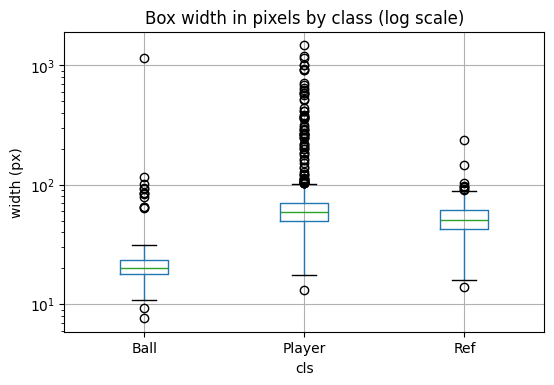

In [15]:
display(df.groupby("cls")[["w_px", "h_px"]].agg(["median", "min", "max"]).round(1))

df.boxplot(column="w_px", by="cls", figsize=(6, 4))
plt.yscale("log")
plt.suptitle("")
plt.title("Box width in pixels by class (log scale)")
plt.ylabel("width (px)")
plt.savefig("../outputs/box_width_by_class.png", dpi=150)
plt.show()

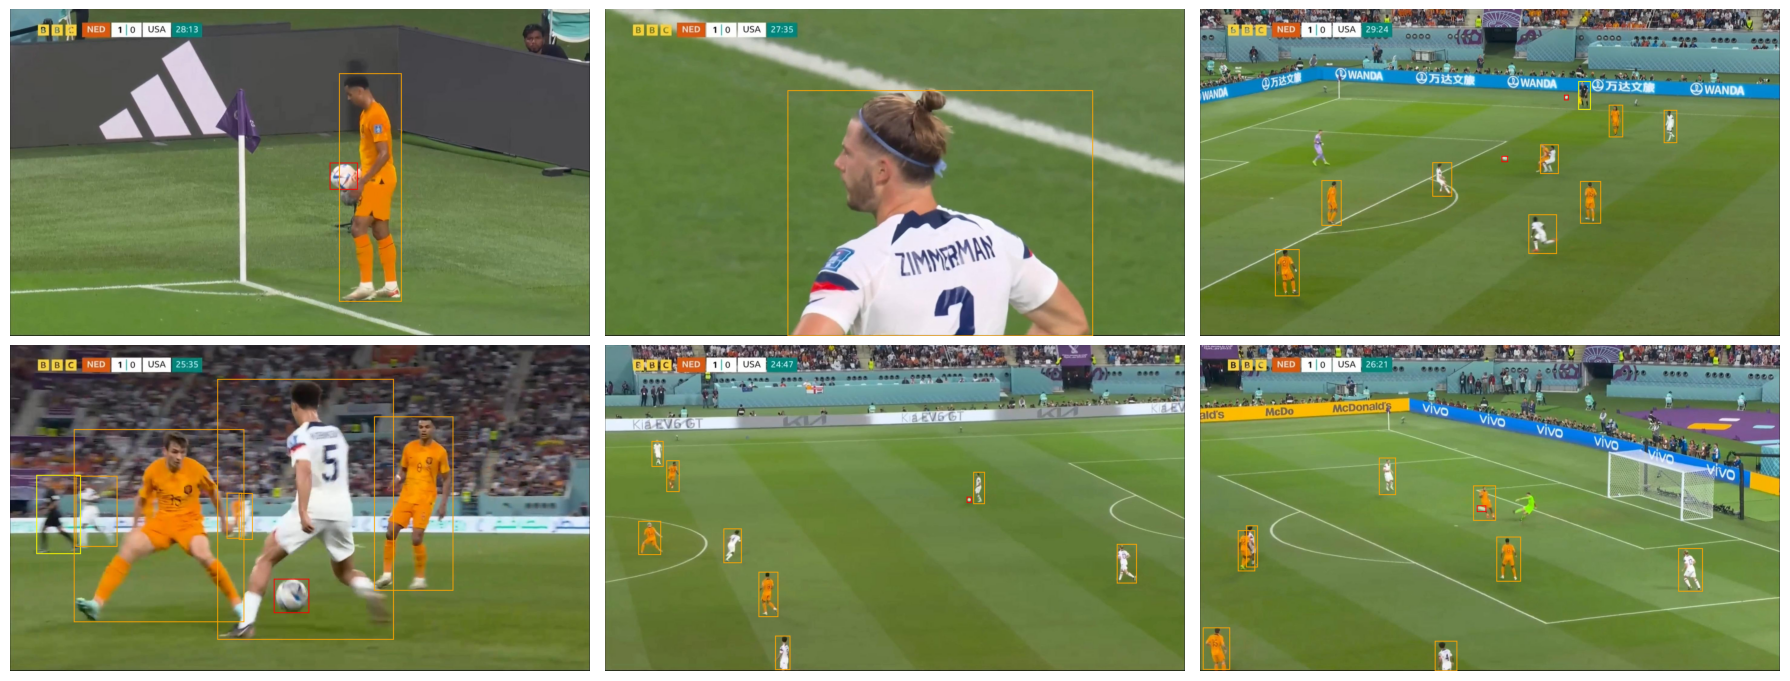

In [16]:
import random
from PIL import ImageDraw

colors = {"Ball": "red", "Player": "orange", "Ref": "yellow"}
files = random.sample(sorted((DET / "train" / "labels").glob("*.txt")), 6)

fig, axes = plt.subplots(2, 3, figsize=(18, 7))
for ax, lbl in zip(axes.ravel(), files):
    img = Image.open(next((DET / "train" / "images").glob(lbl.stem + ".*"))).convert("RGB")
    W, H = img.size
    d = ImageDraw.Draw(img)
    for line in lbl.read_text().splitlines():
        p = line.split()
        if len(p) < 5:
            continue
        c = names[int(p[0])]
        cx, cy, w, h = (float(v) for v in p[1:5])
        d.rectangle([(cx - w/2) * W, (cy - h/2) * H, (cx + w/2) * W, (cy + h/2) * H],
                    outline=colors[c], width=3)
    ax.imshow(img)
    ax.axis("off")
plt.tight_layout()
plt.savefig("../outputs/ground_truth_samples.png", dpi=150)
plt.show()

In [17]:
big_ball = df[(df.cls == "Ball") & (df.w_px > 60)]
big_any = df[df.w_px > 0.10 * df.img_w]

print("Ball boxes wider than 60 px:")
display(big_ball)
print("Any box wider than 10% of image width:")
display(big_any)

all_labels = {p.stem for s in ["train", "valid", "test"] for p in (DET / s / "labels").glob("*.txt")}
labeled = set(df.file)
print("Images with no boxes at all:", len(all_labels - labeled))

Ball boxes wider than 60 px:


,split,file,cls,w_px,h_px,img_w,img_h
29,train,USA_NED-Qatar2022_mp4-113_jpg.rf.d371203c5f57a...,Ball,116.97000,112.490000,1920,1080
225,train,USA_NED-Qatar2022_mp4-186_jpg.rf.a321da5e47a80...,Ball,85.97000,115.750000,1920,1080
287,train,USA_NED-Qatar2022_mp4-1_jpg.rf.4e41e150ef522f3...,Ball,1156.19089,884.244055,1920,1080
678,train,USA_NED-Qatar2022_mp4-382_jpg.rf.d610fbfe3a862...,Ball,100.98000,106.220000,1920,1080
752,train,USA_NED-Qatar2022_mp4-428_jpg.rf.17e8b184d1fab...,Ball,93.15000,88.490000,1920,1080
754,train,USA_NED-Qatar2022_mp4-431_jpg.rf.2c2b758b8c909...,Ball,83.76000,79.130000,1920,1080
819,train,USA_NED-Qatar2022_mp4-461_jpg.rf.dbc4bbbf29de0...,Ball,84.53000,99.310000,1920,1080
821,train,USA_NED-Qatar2022_mp4-470_jpg.rf.bd435b176f577...,Ball,91.27000,88.340000,1920,1080
914,train,USA_NED-Qatar2022_mp4-519_jpg.rf.d5dc6a959626a...,Ball,65.64000,63.000000,1920,1080
931,train,USA_NED-Qatar2022_mp4-523_jpg.rf.e7653ca0a04ac...,Ball,64.86000,59.250000,1920,1080


Any box wider than 10% of image width:


,split,file,cls,w_px,h_px,img_w,img_h
26,train,USA_NED-Qatar2022_mp4-113_jpg.rf.d371203c5f57a...,Player,262.44000,574.660000,1920,1080
28,train,USA_NED-Qatar2022_mp4-113_jpg.rf.d371203c5f57a...,Player,563.15000,637.450000,1920,1080
30,train,USA_NED-Qatar2022_mp4-113_jpg.rf.d371203c5f57a...,Player,583.77000,860.320000,1920,1080
274,train,USA_NED-Qatar2022_mp4-1_jpg.rf.4e41e150ef522f3...,Player,287.00000,524.000000,1920,1080
276,train,USA_NED-Qatar2022_mp4-1_jpg.rf.4e41e150ef522f3...,Player,591.00000,867.000000,1920,1080
278,train,USA_NED-Qatar2022_mp4-1_jpg.rf.4e41e150ef522f3...,Player,436.00000,763.000000,1920,1080
279,train,USA_NED-Qatar2022_mp4-1_jpg.rf.4e41e150ef522f3...,Player,516.00000,854.000000,1920,1080
280,train,USA_NED-Qatar2022_mp4-1_jpg.rf.4e41e150ef522f3...,Player,641.00000,431.000000,1920,1080
281,train,USA_NED-Qatar2022_mp4-1_jpg.rf.4e41e150ef522f3...,Player,710.00000,631.000000,1920,1080
282,train,USA_NED-Qatar2022_mp4-1_jpg.rf.4e41e150ef522f3...,Player,683.00000,721.000000,1920,1080


Images with no boxes at all: 2


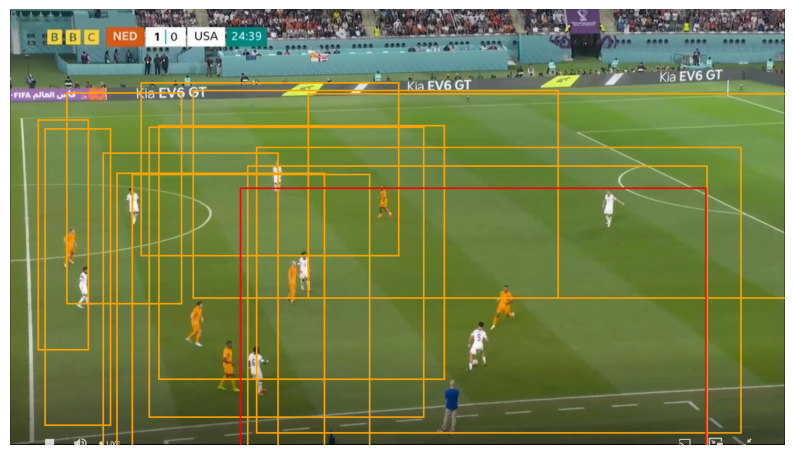

In [18]:
def show(split, stem_start):
    lbl = next((DET / split / "labels").glob(stem_start + "*.txt"))
    img = Image.open(next((DET / split / "images").glob(lbl.stem + ".*"))).convert("RGB")
    W, H = img.size
    d = ImageDraw.Draw(img)
    for line in lbl.read_text().splitlines():
        p = line.split()
        if len(p) < 5: continue
        c = names[int(p[0])]
        cx, cy, w, h = (float(v) for v in p[1:5])
        d.rectangle([(cx-w/2)*W, (cy-h/2)*H, (cx+w/2)*W, (cy+h/2)*H], outline=colors[c], width=4)
    plt.figure(figsize=(10, 6)); plt.imshow(img); plt.axis("off");plt.savefig("../outputs/ground_truth_sample.png", dpi=150); plt.show()

show("train", "USA_NED-Qatar2022_mp4-1_jpg")

In [19]:
for s in ["train", "valid", "test"]:
    for p in (DET / s / "labels").glob("*.txt"):
        if p.stem not in set(df.file):
            print(s, p.stem)

train USA_NED-Qatar2022_mp4-556_jpg.rf.d7dded53de207c12267f0ad5165d48d5
valid USA_NED-Qatar2022_mp4-456_jpg.rf.a27ec6a775dba3117d854e5678219abb
